<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [120]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

#### Add your code below following the instructions given in the course to complete the peer graded assignment


# Task 1: Familiarize Yourself with the Dataset
1. Display the first 5 rows of the dataset.
2. Display the data types of each column.
3. Check for missing values in each column.
4. Check for duplicate rows.
5. Display the correlation matrix of the dataset.

In [126]:
# Task 1-1: Display the first 5 rows of the dataset.
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [127]:
# Task 1-2: Display the data types of each column.
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

In [128]:
# Task 1-3: Check for missing values in each column.
missing_values = boston_df.isnull().sum()
missing_values

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

In [129]:
# Task 1-4: Check for duplicate rows.
duplicate_count = boston_df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

Number of duplicate rows found: 0


In [130]:
# Task 1-5: Display the correlation matrix of the dataset.
boston_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


# Task 2: Generate Descriptive Statistics and Visualizations
1. Display descriptive statistics of the dataset.
2. Create a boxplot for MEDV (Median value of owner-occupied homes).
3. Create a bar plot for CHAS (Charles River dummy variable).
4. Discretize AGE into three groups and create a boxplot of MEDV versus these groups:
5. Create a scatter plot showing the relationship between NOX (nitric oxide concentrations) and INDUS (non-retail business acres).
6. Create a histogram for PTRATIO (pupil-teacher ratio).

In [131]:
# Task 2-1: Display descriptive statistics of the dataset.
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


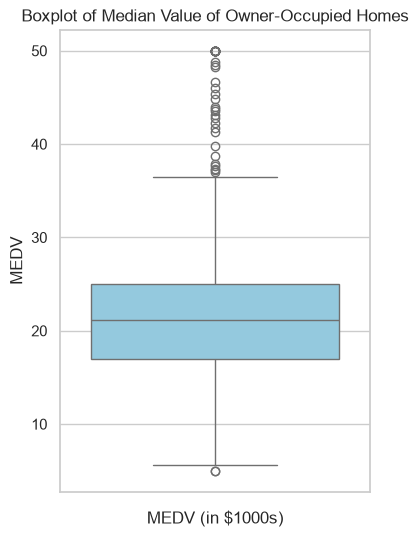

In [134]:
# Task 2-2: Create a boxplot for MEDV (Median value of owner-occupied homes).
sns.set_theme(style = "whitegrid")
pyplot.figure(figsize = (4,6))
sns.boxplot(y="MEDV", data=boston_df, color="skyblue")
pyplot.xlabel("MEDV (in $1000s)")
pyplot.title("Boxplot of Median Value of Owner-Occupied Homes")
pyplot.show()

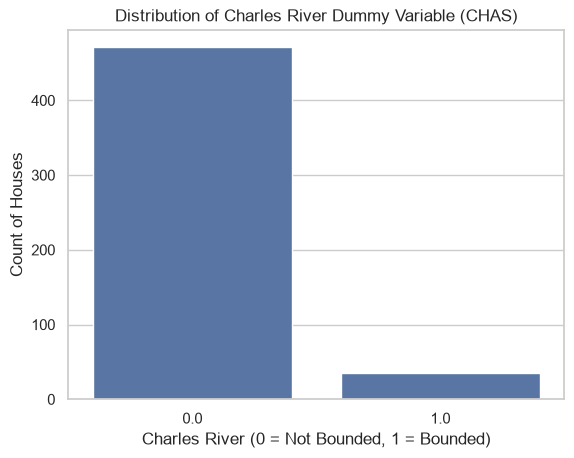

In [135]:
# Task 2-3: Create a bar plot for CHAS (Charles River dummy variable).
sns.set_theme(style = "whitegrid")
sns.countplot(x="CHAS", data=boston_df)
pyplot.xlabel("Charles River (0 = Not Bounded, 1 = Bounded)")
pyplot.ylabel("Count of Houses")
pyplot.title("Distribution of Charles River Dummy Variable (CHAS)")
pyplot.show()

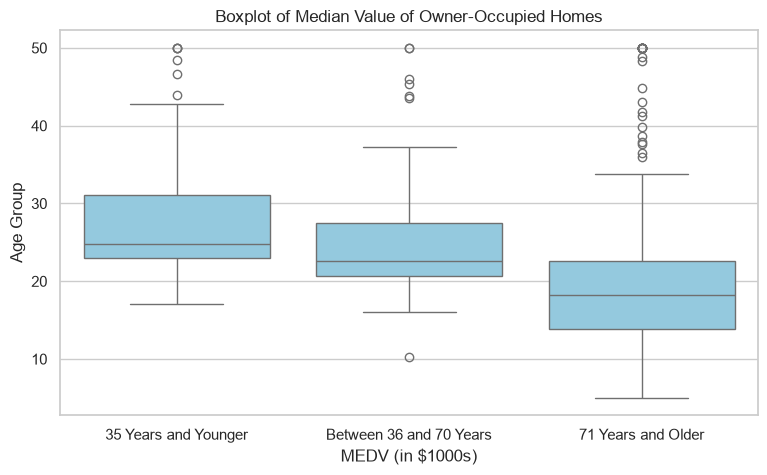

In [154]:
# Task 2-4: Discretize AGE into three groups and create a boxplot of MEDV versus these groups:
boston_df["AGE_GROUP"] = None
boston_df.loc[(boston_df["AGE"] <= 35), "AGE_GROUP"] = "35 Years and Younger"
boston_df.loc[(boston_df["AGE"] > 35) & (boston_df["AGE"] <= 70), "AGE_GROUP"] = "Between 36 and 70 Years"
boston_df.loc[(boston_df["AGE"] > 70), "AGE_GROUP"] = "71 Years and Older"

sns.set_theme(style = "whitegrid")
pyplot.figure(figsize = (9,5))
sns.boxplot(y="MEDV",
            x="AGE_GROUP",
            data=boston_df,
            order=["35 Years and Younger", "Between 36 and 70 Years", "71 Years and Older"],
            color="skyblue")
pyplot.xlabel("MEDV (in $1000s)")
pyplot.ylabel("Age Group")
pyplot.title("Boxplot of Median Value of Owner-Occupied Homes")
pyplot.show()

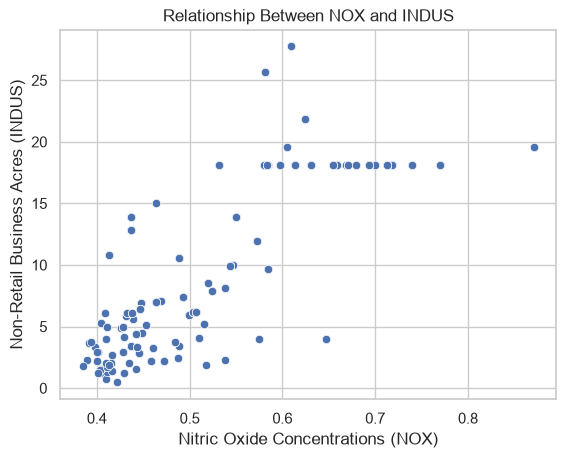

In [141]:
# Task 2-5: Create a scatter plot showing the relationship between NOX (nitric oxide concentrations) and INDUS (non-retail business acres).
sns.set_theme(style = "whitegrid")
sns.scatterplot(x="NOX", y="INDUS", data=boston_df)
pyplot.xlabel("Nitric Oxide Concentrations (NOX)")
pyplot.ylabel("Non-Retail Business Acres (INDUS)")
pyplot.title("Relationship Between NOX and INDUS")
pyplot.show()

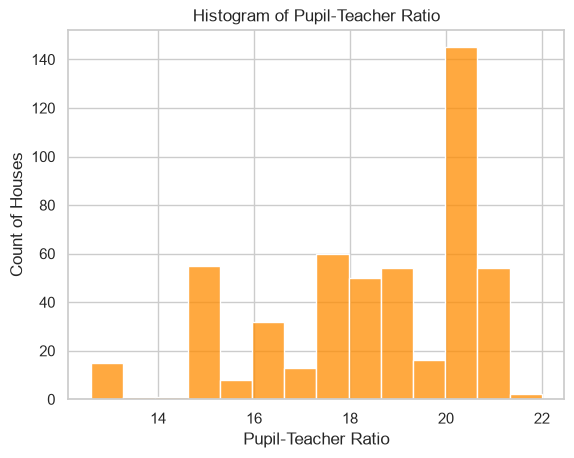

In [148]:
# Task 2-6: Create a histogram for PTRATIO (pupil-teacher ratio).
sns.set_theme(style = "whitegrid")
sns.histplot(x="PTRATIO", data=boston_df, color="darkorange")
pyplot.xlabel("Pupil-Teacher Ratio")
pyplot.ylabel("Count of Houses")
pyplot.title("Histogram of Pupil-Teacher Ratio")
pyplot.show()

# Task 3: Apply Statistical Tests
1. Use Levene’s test to check if the variances of MEDV for homes bounded by the Charles River (CHAS = 1) and those not bounded (CHAS = 0) are equal.
2. Perform a T-test to determine if there is a significant difference in MEDV between homes bounded and not bounded by the Charles River.
3. Conduct an ANOVA test to compare MEDV among the three AGE groups created earlier.
4. Perform a Pearson correlation test to assess the relationship between NOX and INDUS.
5. Fit a simple linear regression model to evaluate the impact of DIS (distance to employment centres) on MEDV. Report and interpret the regression results.

In [149]:
# Task 3-1: Use Levene’s test to check if the variances of MEDV for homes bounded by the Charles River (CHAS = 1) and those not bounded (CHAS = 0) are equal.
levene_result = scipy.stats.levene(boston_df[boston_df["CHAS"] == 1]["MEDV"],
                   boston_df[boston_df["CHAS"] == 0]["MEDV"],
                   center = "mean")
print(levene_result)
print("** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that \
the variances of MEDV bounded by the Charles River and those not bounded are not equal. **")

LeveneResult(statistic=np.float64(8.75190489604598), pvalue=np.float64(0.0032381193676394257))
** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that the variances of MEDV bounded by the Charles River and those not bounded are not equal. **


In [150]:
# Task 3-2: Perform a T-test to determine if there is a significant difference in MEDV between homes bounded and not bounded by the Charles River.
t_test_result = scipy.stats.ttest_ind(boston_df[boston_df["CHAS"] == 1]["MEDV"],
                      boston_df[boston_df["CHAS"] == 0]["MEDV"],
                      equal_var=False)
print(t_test_result)
print("** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that \
there is a significant difference in MEDV between homes bounded and not bounded by the Charles River. **")

TtestResult(statistic=np.float64(3.113291312794837), pvalue=np.float64(0.003567170098137519), df=np.float64(36.876408797611994))
** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that there is a significant difference in MEDV between homes bounded and not bounded by the Charles River. **


In [155]:
# Task 3-3: Conduct an ANOVA test to compare MEDV among the three AGE groups created earlier.
fortyfive_low = boston_df[boston_df["AGE_GROUP"] == "35 Years and Younger"]["MEDV"]
fortyfive_seventyseven = boston_df[boston_df["AGE_GROUP"] == "Between 36 and 70 Years"]["MEDV"]
seventyseven_high = boston_df[boston_df["AGE_GROUP"] == "71 Years and Older"]["MEDV"]

f_statistic, p_value = scipy.stats.f_oneway(fortyfive_low, fortyfive_seventyseven, seventyseven_high)
print("F_statistics: {0}, P_value: {1}".format(f_statistic, p_value))
print("** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that \
at least one of them differs. **")

F_statistics: 36.40764999196599, P_value: 1.7105011022701404e-15
** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that at least one of them differs. **


In [152]:
# Task 3-4: Perform a Pearson correlation test to assess the relationship between NOX and INDUS.
pearson_result = scipy.stats.pearsonr(boston_df["NOX"], boston_df["INDUS"])
print(pearson_result)
print("** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that \
there is relationship between NOX and INDUS. **")

PearsonRResult(statistic=np.float64(0.763651446920915), pvalue=np.float64(7.913361061241167e-98))
** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that there is relationship between NOX and INDUS. **


In [153]:
# Task 3-5: Fit a simple linear regression model to evaluate the impact of DIS (distance to employment centres) on MEDV. Report and interpret the regression results.
x = boston_df["DIS"]
y = boston_df["MEDV"]
x = sm.add_constant(x)
model = sm.OLS(y, x).fit()
predictions = model.predict()
print(model.summary(), "\n")
print("** Conclusion: P-value is lower than 0.05, so we reject the null hypothesis and conclude that \
there is Also, the coefficient of DIS indicates that the one-unit \
increase of distance to employement centers increases the median home value by about $1,091.60. **")

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        12:39:08   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0